# Synthetic data

What part of a series is predictable? Build a controlled process, inspect its components, then ask a forecaster to predict a genuinely unseen future.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp scenarios

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `scenarios`

### Imports and configuration

In [3]:
#| export scenarios
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any

import numpy as np
import pandas as pd

from timegym.contracts import ForecastTask, Reference
from timegym._internal import _real_array
from timegym.processes import PROCESS_KINDS, resolve_process, generate_process, process_label

### Case — One held-out forecast task and its evaluator-only ground truth.

In [4]:
#| export scenarios
@dataclass
class Case:
    """One held-out forecast task and its evaluator-only ground truth."""

    task: ForecastTask
    observed: pd.DataFrame
    reference: Reference
    manifest: dict[str, Any]


_DEFAULTS = {
    "white_noise": {"mean": 0.0, "sigma": 1.0},
    "trend": {"intercept": 0.0, "slope": 0.1, "sigma": 1.0},
    "seasonal": {"mean": 0.0, "amplitude": 1.0, "period": 12.0, "sigma": 1.0},
    "ar1": {"mean": 0.0, "phi": 0.8, "sigma": 1.0},
    "random_walk": {"intercept": 0.0, "drift": 0.0, "sigma": 1.0},
}

CORE_KINDS = tuple(_DEFAULTS)

### Shared positive integer validation

In [5]:
#| export scenarios
from timegym._internal import positive_int

### Shared seed validation

In [6]:
#| export scenarios
from timegym._internal import nonnegative_int

### Human-readable process labels

Keep kind identifiers stable; make drift explicit in figures and descriptions.

In [7]:
#| export scenarios
def scenario_label(kind: str, parameters=None, *, target_index=None) -> str:
    """Describe a process without replacing its stable machine-readable kind.

    Parameters may be raw scalar/vector values or a resolved case manifest's
    parameter dictionary. A target index selects its drift for a plot facet;
    otherwise a mixed zero/nonzero drift vector is described at case level.
    This formats labels rather than validating a full generator specification.
    Unknown custom kinds are returned unchanged.
    """
    if kind in PROCESS_KINDS:
        return process_label(kind, {} if parameters is None else parameters, target_index=target_index)
    labels = {
        "white_noise": "Gaussian white noise (fixed mean)",
        "trend": "Linear trend + white noise",
        "seasonal": "Seasonality + white noise",
        "ar1": "Stationary AR(1)",
    }
    if kind != "random_walk":
        return labels.get(kind, kind)
    parameters = {} if parameters is None else parameters
    drift = _real_array(parameters.get("drift", 0.0), "drift")
    if drift.ndim > 1 or drift.size == 0 or not np.isfinite(drift).all():
        raise ValueError("drift must be a finite scalar or a nonempty vector")
    if target_index is not None:
        target_index = nonnegative_int(target_index, 'target_index')
        if drift.ndim == 1:
            drift = drift[target_index]
    nonzero = drift != 0
    if not np.any(nonzero):
        return "Random walk without drift"
    if np.all(nonzero):
        return "Random walk with drift"
    return "Random walk (mixed drift across targets)"

### Scenario — A fully specified known-parameter Gaussian data-generating process.

In [8]:
#| export scenarios
@dataclass
class Scenario:
    """A fully specified known-parameter data-generating process.

    Vector-valued location/scale parameters are allowed, with one entry per
    target. ``phi`` and ``period`` are scalar. ``correlation`` is either an
    equicorrelation coefficient or a positive-semidefinite correlation matrix.

    AR(1) starts from its stationary distribution and requires ``abs(phi)<1``.
    White noise fluctuates around a fixed mean; trend and seasonal processes
    add noise independently over time to a deterministic mean. Those shocks
    do not carry into future observations. A random walk instead accumulates
    shocks, starts at ``intercept`` at index zero, and has optional ``drift``
    (zero by default). Its variance grows with the forecast horizon. Targets
    may have correlated contemporaneous innovations in every family. Zero
    ``sigma`` gives a degenerate deterministic component. Parameters are exposed
    to the evaluator only; a model receives just ``case.task``. The additional
    composite, Merton, GARCH and hidden-regime processes also support joint
    targets, with explicit dependence laws and reference capabilities.
    """

    kind: str
    context_length: int = 120
    horizon: int = 12
    parameters: dict[str, Any] = field(default_factory=dict)
    n_targets: int = 1
    seed: int = 0

    def __post_init__(self) -> None:
        if self.kind in PROCESS_KINDS:
            self._resolve_process()
        else:
            self._resolve()

    def _resolve_process(self):
        return resolve_process(self.kind, self.parameters, self.context_length,
                               self.horizon, self.n_targets, self.seed)

    @property
    def display_name(self) -> str:
        """Parameter-aware label; ``kind`` remains the stable scenario identifier."""
        if self.kind in PROCESS_KINDS:
            return process_label(self.kind, self._resolve_process())
        parameters, _, _, _, _ = self._resolve()
        return scenario_label(self.kind, parameters)

    def _resolve(self) -> tuple[dict, np.ndarray, int, int, int]:
        if self.kind not in _DEFAULTS:
            raise ValueError(f"Unknown scenario {self.kind!r}; choose from {tuple(_DEFAULTS)}")
        length = positive_int(self.context_length, 'context_length')
        horizon = positive_int(self.horizon, 'horizon')
        dimensions = positive_int(self.n_targets, 'n_targets')
        nonnegative_int(self.seed, 'seed')
        if not isinstance(self.parameters, dict):
            raise TypeError("parameters must be a dictionary")
        unsupported = set(self.parameters) - set(_DEFAULTS[self.kind]) - {"correlation"}
        if unsupported:
            raise ValueError(f"Unsupported parameters for {self.kind}: {sorted(unsupported)}")
        parameters = {**_DEFAULTS[self.kind], **self.parameters}
        correlation = _real_array(parameters.pop("correlation", 0.0), "correlation")
        if correlation.ndim == 0:
            rho = float(correlation)
            lower = -1.0 / (dimensions - 1) if dimensions > 1 else -1.0
            if not np.isfinite(rho) or not lower <= rho <= 1.0:
                raise ValueError(f"Scalar correlation must be between {lower} and 1")
            correlation = np.full((dimensions, dimensions), rho)
            np.fill_diagonal(correlation, 1.0)
        if correlation.shape != (dimensions, dimensions) or not np.isfinite(correlation).all():
            raise ValueError("correlation must have shape (n_targets, n_targets) and finite entries")
        if not np.allclose(correlation, correlation.T, atol=1e-12, rtol=1e-10):
            raise ValueError("correlation must be symmetric")
        if not np.allclose(np.diag(correlation), 1.0, atol=1e-12, rtol=1e-10) or np.linalg.eigvalsh(correlation).min() < -1e-10:
            raise ValueError("correlation must have unit diagonal and be positive semidefinite")
        resolved: dict[str, Any] = {}
        for name, raw in parameters.items():
            value = _real_array(raw, name)
            if not np.isfinite(value).all():
                raise ValueError(f"{name} must be finite")
            if name in {"phi", "period"}:
                if value.ndim != 0:
                    raise ValueError(f"{name} must be scalar")
                resolved[name] = float(value)
            else:
                if value.ndim == 0:
                    value = np.full(dimensions, float(value))
                if value.shape != (dimensions,):
                    raise ValueError(f"{name} must be scalar or have one entry per target")
                resolved[name] = value
        if np.any(resolved["sigma"] < 0):
            raise ValueError("sigma must be nonnegative")
        if "phi" in resolved and not abs(resolved["phi"]) < 1:
            raise ValueError("Stationary ar1 requires abs(phi) < 1")
        if "period" in resolved and resolved["period"] <= 0:
            raise ValueError("period must be positive")
        return resolved, correlation, length, horizon, dimensions

    def generate(self, seed: int | None = None) -> Case:
        """Generate context and held-out observations without global RNG state."""
        if self.kind in PROCESS_KINDS:
            self._resolve_process()
            run_seed = nonnegative_int(self.seed if seed is None else seed, 'seed')
            return generate_process(self.kind, self.parameters, self.context_length,
                                    self.horizon, self.n_targets, run_seed)
        p, correlation, length, horizon, dimensions = self._resolve()
        run_seed = nonnegative_int(self.seed if seed is None else seed, 'seed')
        rng = np.random.default_rng(run_seed)
        innovation_cov = correlation * np.outer(p["sigma"], p["sigma"])
        eigenvalues, eigenvectors = np.linalg.eigh(innovation_cov)
        factor = eigenvectors * np.sqrt(np.maximum(eigenvalues, 0.0))
        noise = rng.standard_normal((length + horizon, dimensions)) @ factor.T
        time = np.arange(length + horizon, dtype=float)[:, None]
        future_steps = np.arange(1, horizon + 1, dtype=float)[:, None]
        temporal_cov = np.eye(horizon)
        conditioning: dict[str, Any] = {
            "observed_through": length - 1,
            "known_generator_parameters": True,
            "future_observations_used": False,
        }

        if self.kind == "white_noise":
            signal = np.broadcast_to(p["mean"], noise.shape)
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "trend":
            signal = p["intercept"] + p["slope"] * time
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "seasonal":
            signal = p["mean"] + p["amplitude"] * np.sin(2 * np.pi * time / p["period"])
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "ar1":
            phi = p["phi"]
            values = np.empty_like(noise)
            values[0] = p["mean"] + noise[0] / np.sqrt(1.0 - phi * phi)
            for t in range(1, len(values)):
                values[t] = p["mean"] + phi * (values[t - 1] - p["mean"]) + noise[t]
            last = values[length - 1].copy()
            conditional_mean = p["mean"] + phi ** future_steps * (last - p["mean"])
            power = np.arange(horizon)[:, None] - np.arange(horizon)[None, :]
            loading = np.zeros((horizon, horizon))
            lower_triangle = power >= 0
            loading[lower_triangle] = phi ** power[lower_triangle]
            temporal_cov = loading @ loading.T
            conditioning["last_observed"] = last.tolist()
            conditioning["initialization"] = "stationary_distribution"
        else:  # random_walk
            values = np.empty_like(noise)
            values[0] = p["intercept"]
            for t in range(1, len(values)):
                values[t] = values[t - 1] + p["drift"] + noise[t]
            last = values[length - 1].copy()
            conditional_mean = last + future_steps * p["drift"]
            temporal_cov = np.minimum.outer(np.arange(1, horizon + 1), np.arange(1, horizon + 1))
            conditioning["last_observed"] = last.tolist()
            conditioning["initialization"] = "intercept_at_index_zero"

        names = ("y",) if dimensions == 1 else tuple(f"y{i}" for i in range(dimensions))
        context_index = pd.RangeIndex(length)
        future_index = pd.RangeIndex(length, length + horizon)
        context = pd.DataFrame(values[:length].copy(), index=context_index, columns=names)
        observed = pd.DataFrame(values[length:].copy(), index=future_index, columns=names)
        covariance = np.kron(temporal_cov, innovation_cov)
        variance = np.diag(covariance).reshape(horizon, dimensions).copy()
        resolved_parameters = {name: value.tolist() if isinstance(value, np.ndarray) else value for name, value in p.items()}
        resolved_parameters["correlation"] = correlation.tolist()
        manifest = {
            "schema_version": 1,
            "kind": self.kind,
            "context_length": length,
            "horizon": horizon,
            "n_targets": dimensions,
            "target_names": list(names),
            "seed": run_seed,
            "parameters": resolved_parameters,
            "reference_kind": "analytic_conditional",
            "conditioning": conditioning.copy(),
            "array_order": "horizon_major_C",
        }
        reference = Reference(
            mean=conditional_mean,
            variance=variance,
            covariance=covariance,
            index=future_index.copy(),
            target_names=names,
            conditioning=conditioning,
        )
        return Case(ForecastTask(context, future_index), observed, reference, manifest)

## Build `data.synthetic`

### Imports and configuration

In [9]:
# Preserve these live notebook definitions while exporting a second module below.
_notebook_scenario_types = (Case, Scenario)

In [10]:
#| export data.synthetic
from timegym.contracts import Reference
from timegym.scenarios import CORE_KINDS, Case, Scenario

__all__ = ["Case", "Reference", "Scenario", "default_scenarios"]

### default_scenarios — Return five fresh scenario specifications; generation is always explicit.

In [11]:
#| export data.synthetic
def default_scenarios(context_length=120, horizon=12, *, n_targets=1, seed=0):
    """Return five fresh scenario specifications; generation is always explicit.

    The same supplied seed is recorded in each specification. Use independent
    replicate seeds when aggregating experimental results.
    """
    return [
        Scenario(kind, context_length=context_length, horizon=horizon, n_targets=n_targets, seed=seed)
        for kind in CORE_KINDS
    ]

## Separate a signal from observation noise

In [12]:
# The package imports above are correct for exported data.synthetic, but this
# experiment must exercise the source classes we just defined in this kernel.
Case, Scenario = _notebook_scenario_types
assert Case.__module__ == Scenario.__module__ == __name__

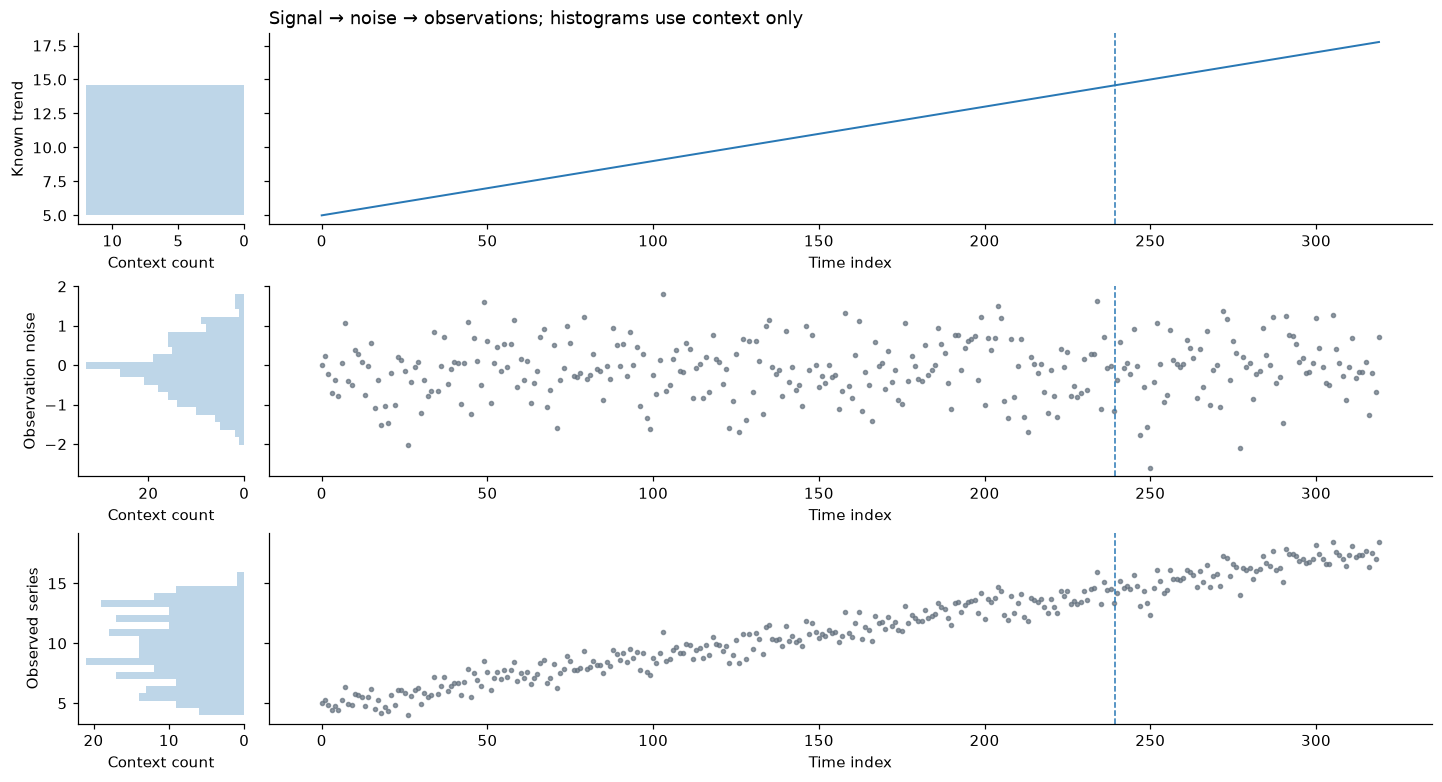

In [13]:
specification = Scenario('trend', context_length=240, horizon=80,
                         parameters={'intercept': 5., 'slope': .04, 'sigma': .8})
case = specification.generate(seed=7)
assert type(specification) is Scenario
assert type(case) is Case
values = pd.concat([case.task.context, case.observed])['y']
signal = 5. + .04 * values.index.to_numpy()
noise = values.to_numpy() - signal
fig, axes = plt.subplots(3, 2, figsize=(13, 7), width_ratios=[1, 7],
                         sharey='row', layout='constrained')
for row, (label, component, deterministic) in enumerate([
    ('Known trend', signal, True), ('Observation noise', noise, False),
    ('Observed series', values.to_numpy(), False)]):
    hist, ax = axes[row]
    hist.hist(component[:240], bins=20, orientation='horizontal', color='#2878b5', alpha=.3)
    hist.invert_xaxis()
    hist.set(ylabel=label, xlabel='Context count')
    hist.spines[['top', 'right']].set_visible(False)
    if deterministic:
        ax.plot(values.index, component, color='#2878b5', lw=1.3)
    else:
        ax.scatter(values.index, component, s=7, color='#64717e', alpha=.7)
    ax.axvline(239.5, color='#2878b5', ls='--', lw=1)
    ax.set_xlabel('Time index')
axes[0, 1].set_title('Signal → noise → observations; histograms use context only')
plt.show()
np.testing.assert_allclose(case.reference.mean[:, 0], signal[240:])

This decomposition is valid for a deterministic linear trend plus fresh white noise. The same principle applies to fixed sinusoidal seasonality plus white noise. A shock changes one observation; it does not move the future mean. A random walk **accumulates** shocks: each innovation changes the level inherited by subsequent steps. Its optional `drift` is a separate deterministic increment, zero by default. A zero-drift realization can still appear to trend over a finite window.

For AR(1) and random walks, the forecast reference conditions on the last observation; a realized future random path is not an oracle. White noise is independent over time here; multivariate targets may still have correlated shocks at the same time.


**Seasonality is not drift.** Seasonality repeats; process drift is an expected increment. A change in slope, seasonal amplitude/period/phase, or noise law is a change in the mechanism. A fixed seasonal cycle or fixed-parameter hidden regime process need not imply concept drift. See [controlled compositions and financial stresses](26_composed_and_financial_stresses.ipynb).

## See several draws together

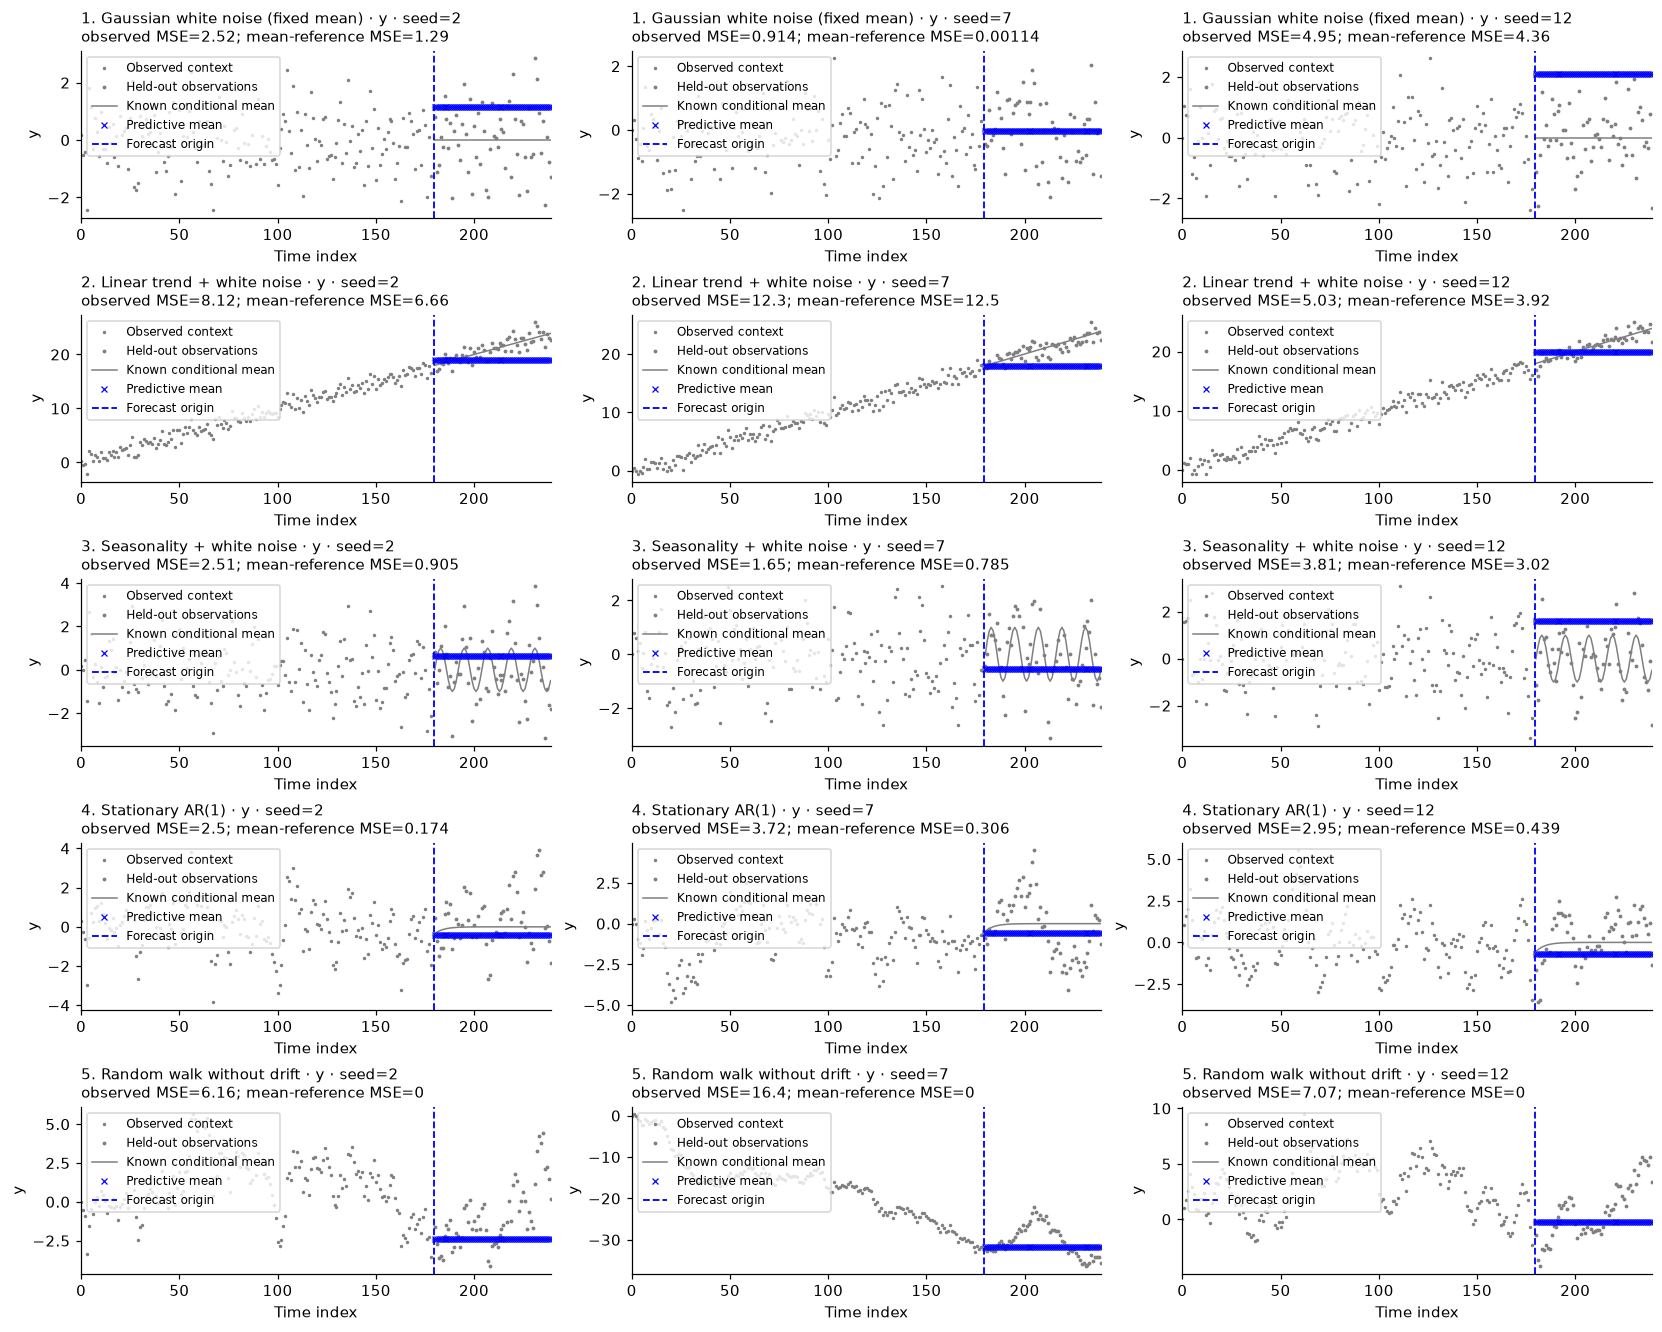

In [14]:
from timegym import Pipeline, NaiveForecaster
run = Pipeline(NaiveForecaster(strategy='last')).run(
    default_scenarios(context_length=180, horizon=60), seeds=[2, 7, 12])
assert all(type(entry.case) is Case for entry in run.cases)
run.plot_forecasts(figsize=(15, 12));
plt.show()

Rows hold the generating family fixed; columns change the seed. Blue crosses are point forecasts. Gray dots are stochastic observations. A correct forecast mean need not follow each realized shock.

## Edit, run, export

After editing a source cell, **restart this kernel and Run All**. This refreshes the local definitions, the development bindings between modules in this chapter, and the nearby examples. Ordinary Run All does not export files.

Changes to code owned by another chapter require saving that source notebook, running `python tools/export_notebooks.py`, and restarting this kernel before importing the updated package. Runtime provenance describes the exported package, not unexported edits.

Try one implementation or parameter change, rerun this chapter, and inspect the figure or assertion. Save the notebook before exporting.